# How dark is a Copenhagen winter? Copenhagen vs Suzhou

Questions:
1. How many hours of daylight does each city get in each month?
2. How many days a year does Copenhagen have less than 8 hours of daylight?
3. Which month is the darkest and coldest in each city?
4. Does more daylight mean more actual sunshine?

Data: daily weather for 2023–2025 from the Open-Meteo Historical Weather API (free, no API key).

Pipeline: API (Python) → clean with pandas → store in SQLite → answer the questions with SQL → charts.

## 0. Setup

All of these come with Anaconda. `sqlite3` is built into Python.

In [1]:
import requests
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

## 1. Get the data from the API

Each city needs its latitude, longitude and time zone. The API returns JSON; the daily values are under the key `"daily"`.

Variables we ask for:
- `daylight_duration`: seconds between sunrise and sunset
- `sunshine_duration`: seconds of actual sunshine
- `temperature_2m_mean`: mean temperature (°C)
- `precipitation_sum`: rain/snow (mm)

In [2]:
CITIES = {
    "Copenhagen": {"latitude": 55.68, "longitude": 12.57, "timezone": "Europe/Copenhagen"},
    "Suzhou":     {"latitude": 31.30, "longitude": 120.62, "timezone": "Asia/Shanghai"},
}

URL = "https://archive-api.open-meteo.com/v1/archive"
DAILY_VARS = "daylight_duration,sunshine_duration,temperature_2m_mean,precipitation_sum"

def get_city_weather(city, info, start="2023-01-01", end="2025-12-31"):
    params = {
        "latitude": info["latitude"],
        "longitude": info["longitude"],
        "timezone": info["timezone"],
        "start_date": start,
        "end_date": end,
        "daily": DAILY_VARS,
    }
    response = requests.get(URL, params=params)
    response.raise_for_status()
    data = response.json()

    df = pd.DataFrame(data["daily"])
    df["city"] = city

    return df

In [3]:
frames = [get_city_weather(city, info) for city, info in CITIES.items()]
weather = pd.concat(frames, ignore_index=True)
weather.head()

,time,daylight_duration,sunshine_duration,temperature_2m_mean,precipitation_sum,city
0,2023-01-01,25742.01,7200.00,9.3,5.0,Copenhagen
1,2023-01-02,25831.02,0.00,7.2,8.6,Copenhagen
2,2023-01-03,25927.85,23866.57,4.6,0.0,Copenhagen
3,2023-01-04,26032.23,0.00,7.0,21.7,Copenhagen
4,2023-01-05,26143.88,0.00,4.6,1.5,Copenhagen


## 2. Clean and check the data

Before storing anything, check that the numbers make sense. This is the "make sure the numbers match" part.

TODO:
- Convert `daylight_duration` and `sunshine_duration` from seconds to hours (divide by 3600) and name the new columns `daylight_hours` and `sunshine_hours`.
- Convert `time` to a date and add a `year` and a `month` column.
- Check: how many rows per city? (3 years ≈ 1096 days each)
- Check: any missing values? (`.isna().sum()`)
- Sanity check: Copenhagen daylight should be roughly 7 hours in December and 17–18 hours in June. Is it?

In [4]:
weather["daylight_hours"] = weather["daylight_duration"] / 3600

In [5]:
weather["time"] = pd.to_datetime(weather["time"])
weather["year"] = weather["time"].dt.year
weather["month"] = weather["time"].dt.month
weather["sunshine_hours"] = weather["sunshine_duration"] / 3600

In [6]:
weather["city"].value_counts()

city
Copenhagen    1096
Suzhou        1096
Name: count, dtype: int64

In [7]:
weather.isna().sum()

time                   0
daylight_duration      0
sunshine_duration      0
temperature_2m_mean    0
precipitation_sum      0
city                   0
daylight_hours         0
year                   0
month                  0
sunshine_hours         0
dtype: int64

In [8]:
weather[(weather["city"] == "Copenhagen") & (weather["month"] == 12)]["daylight_hours"].mean()

np.float64(7.146787425328554)

## 3. Store the data in a SQLite database

SQLite keeps the whole database in one file (`weather.db`). `to_sql` writes a DataFrame into a table.

In [9]:
conn = sqlite3.connect("weather.db")

cols = ["city", "time", "year", "month", "daylight_hours", "sunshine_hours",
        "temperature_2m_mean", "precipitation_sum"]
weather[cols].to_sql("weather", conn, if_exists="replace", index=False)

def sql(query):
    return pd.read_sql_query(query, conn)

sql("SELECT * FROM weather LIMIT 5;")

,city,time,year,month,daylight_hours,sunshine_hours,temperature_2m_mean,precipitation_sum
0,Copenhagen,2023-01-01 00:00:00,2023,1,7.150558,2.000000,9.3,5.0
1,Copenhagen,2023-01-02 00:00:00,2023,1,7.175283,0.000000,7.2,8.6
2,Copenhagen,2023-01-03 00:00:00,2023,1,7.202181,6.629603,4.6,0.0
3,Copenhagen,2023-01-04 00:00:00,2023,1,7.231175,0.000000,7.0,21.7
4,Copenhagen,2023-01-05 00:00:00,2023,1,7.262189,0.000000,4.6,1.5


## 4. Answer the questions with SQL

Write each query yourself. Hints refer to the SQLBolt lessons.

### Q1. Average daylight hours per month, for each city
Hint: `AVG(...)`, `GROUP BY` two columns (lessons 10–11), `ORDER BY`. Use `ROUND(..., 1)` to keep one decimal.

In [10]:
q1 = sql("""
SELECT city, month, ROUND(AVG(daylight_hours), 1) AS avg_daylight
FROM weather
GROUP BY city, month
ORDER BY city,month;
""")
q1

,city,month,avg_daylight
0,Copenhagen,1,7.8
1,Copenhagen,2,9.6
2,Copenhagen,3,11.9
3,Copenhagen,4,14.2
4,Copenhagen,5,16.3
5,Copenhagen,6,17.4
6,Copenhagen,7,16.8
7,Copenhagen,8,15.0
8,Copenhagen,9,12.7
9,Copenhagen,10,10.4


### Q2. How many days a year does each city have less than 8 hours of daylight?
Hint: `WHERE` + `COUNT(*)` + `GROUP BY city, year`.

In [11]:
q2 = sql("""
SELECT city, year, COUNT(*) AS dark_days
FROM weather
WHERE daylight_hours < 8
GROUP BY city, year
ORDER BY city, year;
""")
q2

,city,year,dark_days
0,Copenhagen,2023,62
1,Copenhagen,2024,63
2,Copenhagen,2025,61


### Q3. The darkest and the coldest month in each city
Hint: start from your Q1 query and also average the temperature. Then sort and look at the top rows for each city.

In [12]:
q3 = sql("""
SELECT city, month,
       ROUND(AVG(daylight_hours), 1) AS avg_daylight,
       ROUND(AVG(temperature_2m_mean), 1) AS avg_temp
FROM weather
GROUP BY city, month
ORDER BY city, avg_temp ASC;
""")
q3

,city,month,avg_daylight,avg_temp
0,Copenhagen,1,7.8,2.6
1,Copenhagen,2,9.6,3.0
2,Copenhagen,12,7.1,4.6
3,Copenhagen,3,11.9,4.7
4,Copenhagen,11,8.3,6.2
5,Copenhagen,4,14.2,7.7
6,Copenhagen,10,10.4,11.1
7,Copenhagen,5,16.3,12.5
8,Copenhagen,6,17.4,16.1
9,Copenhagen,9,12.7,16.3


### Q4. How much of the daylight is actual sunshine?
Hint: an expression in SELECT (lesson 9): `SUM(sunshine_hours) / SUM(daylight_hours)`, per city and month.

In [13]:
q4 = sql("""
SELECT city, month,
       ROUND(100.0 * SUM(sunshine_hours) / SUM(daylight_hours), 1) AS sunshine_pct
FROM weather
GROUP BY city, month
ORDER BY city, month;
""")
q4

,city,month,sunshine_pct
0,Copenhagen,1,37.1
1,Copenhagen,2,43.1
2,Copenhagen,3,56.8
3,Copenhagen,4,68.7
4,Copenhagen,5,79.3
5,Copenhagen,6,76.4
6,Copenhagen,7,72.9
7,Copenhagen,8,74.2
8,Copenhagen,9,78.9
9,Copenhagen,10,53.4


### Check your SQL against pandas
Compute Q1 again with pandas `groupby` and compare. If the two agree, you can trust the query.

In [14]:
check = weather.groupby(["city", "month"])["daylight_hours"].mean().round(1).reset_index()
check

,city,month,daylight_hours
0,Copenhagen,1,7.8
1,Copenhagen,2,9.6
2,Copenhagen,3,11.9
3,Copenhagen,4,14.2
4,Copenhagen,5,16.3
5,Copenhagen,6,17.4
6,Copenhagen,7,16.8
7,Copenhagen,8,15.0
8,Copenhagen,9,12.7
9,Copenhagen,10,10.4


In [15]:
(check["daylight_hours"].values == q1["avg_daylight"].values).all()

np.True_

## 5. Charts

Chart 1: average daylight hours by month, one line per city (from `q1`).
Chart 2: share of daylight that is sunshine, by month (from `q4`).
Save each chart as a PNG (`plt.savefig("daylight_by_month.png", dpi=150, bbox_inches="tight")`) so it can go into the README.

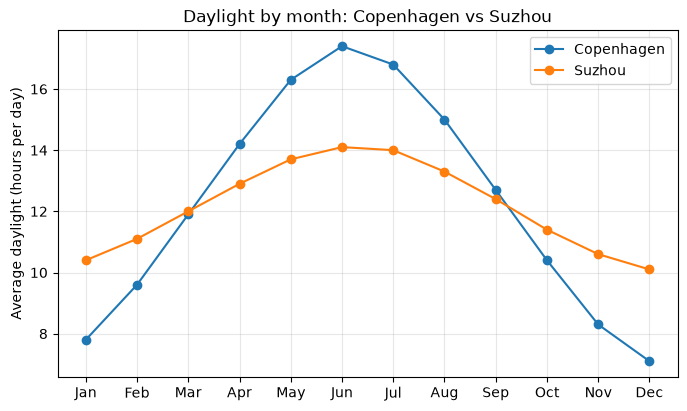

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for city in ["Copenhagen", "Suzhou"]:
    data = q1[q1["city"] == city] 
    ax.plot(data["month"], data["avg_daylight"], marker="o", label=city)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Average daylight (hours per day)")
ax.set_title("Daylight by month: Copenhagen vs Suzhou")
ax.legend()
ax.grid(alpha=0.3)

plt.savefig("daylight_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

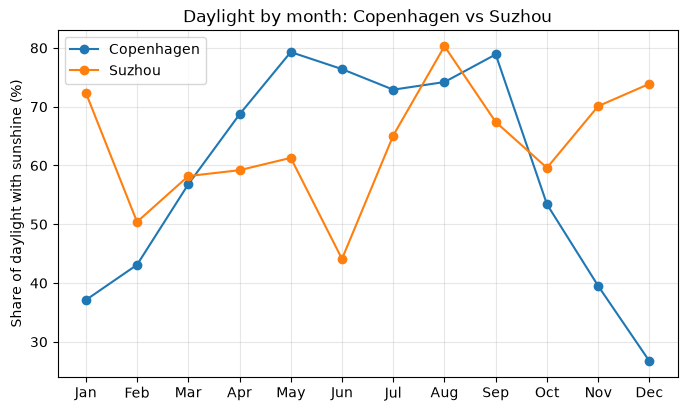

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for city in ["Copenhagen", "Suzhou"]:
    data = q4[q4["city"] == city] 
    ax.plot(data["month"], data["sunshine_pct"], marker="o", label=city)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Share of daylight with sunshine (%)")
ax.set_title("Daylight by month: Copenhagen vs Suzhou")
ax.legend()
ax.grid(alpha=0.3)

plt.savefig("sunshine_share_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

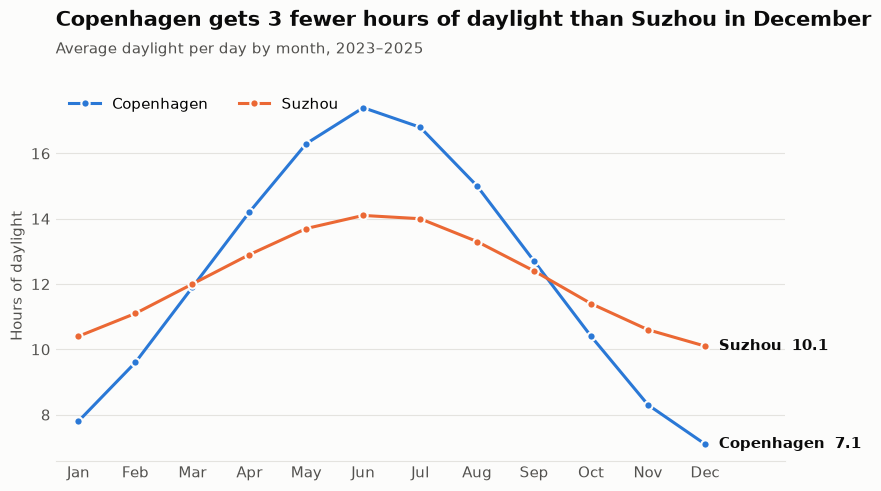

In [18]:
COLORS = {"Copenhagen": "#2a78d6", "Suzhou": "#eb6834"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False,
})

def monthly_line_chart(df, value_col, title, subtitle, ylabel, filename, fmt="{:.1f}"):
    fig, ax = plt.subplots(figsize=(9, 5))
    for city, color in COLORS.items():
        d = df[df["city"] == city].sort_values("month")
        ax.plot(d["month"], d[value_col], color=color, linewidth=2.2,
                marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5,
                label=city, zorder=3)
        last = d.iloc[-1]
        ax.annotate(f"{city}  {fmt.format(last[value_col])}", (12, last[value_col]),
                    xytext=(10, 0), textcoords="offset points",
                    va="center", color=INK, fontsize=11, fontweight="bold")
    ax.set_xticks(range(1, 13), MONTHS)
    ax.set_xlim(0.6, 13.4)
    ax.set_ylabel(ylabel)
    fig.text(0.07, 0.97, title, fontsize=15, fontweight="bold", color=INK, ha="left")
    fig.text(0.07, 0.915, subtitle, fontsize=11, color=INK_2, ha="left")
    ax.legend(loc="upper left", ncols=2, bbox_to_anchor=(0, 1.02))
    fig.subplots_adjust(top=0.84, left=0.07, right=0.88, bottom=0.1)
    fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()

monthly_line_chart(q1, "avg_daylight",
    title="Copenhagen gets 3 fewer hours of daylight than Suzhou in December",
    subtitle="Average daylight per day by month, 2023–2025",
    ylabel="Hours of daylight", filename="daylight_by_month.png")

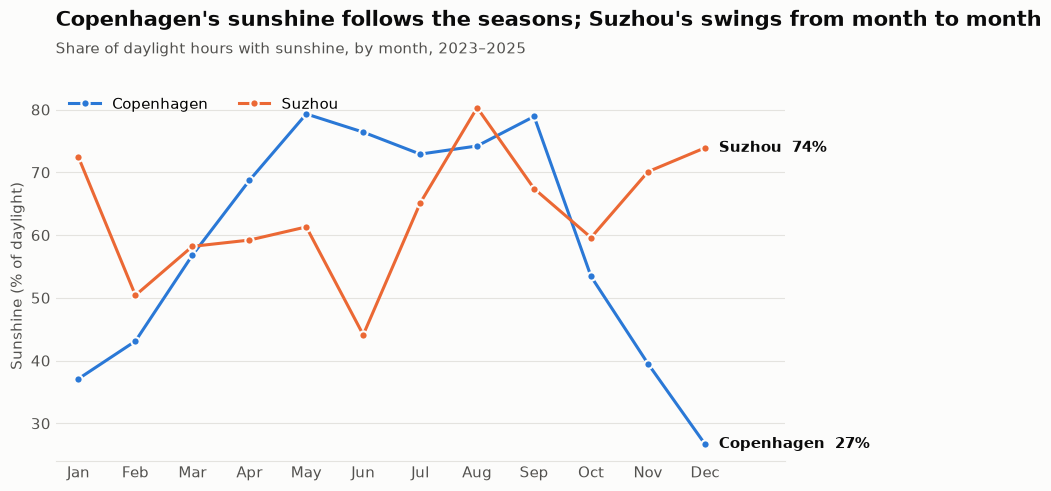

In [19]:
monthly_line_chart(q4, "sunshine_pct",
    title="Copenhagen's sunshine follows the seasons; Suzhou's swings from month to month",
    subtitle="Share of daylight hours with sunshine, by month, 2023–2025",
    ylabel="Sunshine (% of daylight)", filename="sunshine_share_by_month.png",
    fmt="{:.0f}%")

## 6. Findings

Write 3–5 sentences in your own words: what did you find, and what surprised you?

In December, Copenhagen gets only about 7 hours of daylight a day, around 3 hours less than Suzhou.
Copenhagen has about 62 days a year with less than 8 hours of daylight; Suzhou has none.
In both cities the coldest month (January) comes one month after the darkest (December).
In January the two cities are only 2.5°C apart, but Copenhagen has 2.6 fewer hours of daylight. Compared with Suzhou, a Copenhagen winter is mainly dark rather than cold.
Clouds make it darker still: only 27% of Copenhagen's December daylight is sunny. Copenhagen's sunshine follows the seasons, while Suzhou's changes from month to month and drops to 44% in June, during the plum rain season.
Limitation: Open-Meteo's sunshine duration is estimated by a weather model, not measured at a station, so the sunshine figures are approximate.